# Форматы записи последовательностей

## Распишите какие форматы для записи послдеовательностей вы знаете, в чем их сходство и различие, для чего они предназначены? 

Основные форматы записи последовательностей:

FASTA (.fa, .fasta) — минималистичный текстовый формат: строка заголовка (начинается с >) и сама нуклеотидная или белковая последовательность. Используется для компактного хранения и быстрого поиска (BLAST).

FASTQ (.fq, .fastq) — текстовый формат для сырых данных секвенирования (ридов). В отличие от FASTA, дополнительно хранит строку с оценкой качества прочтения каждого нуклеотида.

GenBank (.gb) / EMBL — аннотированные форматы биологических баз данных. Помимо последовательности, содержат метаданные: таксономию, координаты генов, экзонов, кодирующих участков (CDS) и ссылки.

Clustal (.aln) и PHYLIP (.phy) — форматы для множественных выравниваний (MSA), где последовательности приведены к одной длине за счёт гэпов (-). Широко используются для построения филогенетических деревьев.

SAM / BAM — форматы для хранения ридов, уже выровненных на референсный геном (SAM — текстовый, BAM — его сжатый бинарный аналог для быстрой обработки).

Сходство и различия:
Сходство: все форматы предназначены для стандартизированного представления биологических последовательностей и совместимости между биоинформатическими программами.
Различия: заключаются в объёме метаданных (от одного заголовка в FASTA до полной аннотации в GenBank), этапе анализа (сырые риды в FASTQ, картированные в SAM/BAM, выровненные гомологи в PHYLIP) и способе хранения (читаемый текст или бинарный сжатый файл для экономии места).

## Создайте функцию для записи последовательностей из строк в файл вормата .fasta. C помощью этой функции запишите последовательность из переменной seq1 в fasta-файл. Идентификатор и описание для последовательности придумайте самостоятельно. 

In [1]:
seq1= 'ATAGCGACTACCCCTGGCAACCGCGAAGCTCTGCGGTCCCGCGGTCGGGCTACGGGTTTGAGCAAAGCTCCTCTCTTCCCTTCACTTCCCTCCGGACTGGTTTCTTCTTCCTTCCCCCTTCCCCCAACTTCCCTCCACCCCTTCCA'

In [2]:
def write_fasta(filename, id, opisanie, sequence, line_width=60):
    with open(filename, "w", encoding="utf-8") as f:
        f.write(f">{id} {opisanie}\n")
        for i in range(0, len(sequence), line_width):
            f.write(sequence[i:i + line_width] + "\n")

write_fasta(
    filename="seq1.fasta",
    id="seq_001",
    opisanie="Fragment from the Markdown above",
    sequence=seq1
)

## Выведите содержимое файла "homologene.fa". Сначала словестно охарактеризйте его содержимое. После чего проанализируйте все последовательности файла с помощью Biopython: рассчитайте длину, gc-состав, молекулярную массу, нуклеотидный состав и найдите позиции старт-кодонов. 

In [3]:
with open("homologene.fa", "r", encoding="utf-8") as f:
    print(f.read())

>[Homo sapiens]
GTCTTTTCAGCTCTTGTGCAATAATTTCGGAGACTCGGCCTACCAACAACACTTCTAATAGGTAGGTTAT
TTCTAAGCTAAGTTAATTCATTAACATCATACCTTATATTTATCACCTAGGTATTTCTTATTTACTCCTC
>[Cebus capucinus]
GTCTTTTCAGCTCTTGTGCGGCCTACCAACAACACTTCTAATCAATAATTTCGGAGACTAGGTAGGTTAT
TTCTAAGCTAAGTTAATTCATTAACATCATACCTTATATTTATCACCTAGGTATTTCTTATTTACTCCTC
>[Felis catus]
GTCTTTTCAGCTCTTTTCTAATCAATAATTTCGGAGACTAGGTAGGGTGCGGCCTACCAACAACACTTAT
TTCTAAGCTAAGTTAATTTATATTTATCATCATTAACATCATACCCCTAGGTATTTCTTATTTACTCCTC
>[Trionyx triunguis]
GTCTTTTCACAATAATTTCGGAGACTAGGTAGGCTCTTTTCTAATGGTGCGGCCTACCAACAACACTTAT
TTCTAAGCTAAGTTAATTTATATTTATCATCATTAACATCATACCCCTAGGTATTTCTTATTTACTCCTC
>[Halicephalobus mephisto]
GTCTTTTCACAATAATTTCGGAGACTAGGTAGGCTCTTTTCTAATGGTGCGGCCTACCAACAACACTTAT
TTCTAAGCTAAGTTTTTATCATCATTAACATCAATTTATAATACCCCTAGGTATTTCTTATTTACTCCTC
>[Drosophila melanogaster]
GTCTTTTCACAATAATTTCGGAGACTAGGTAGGCTCTTTTCTAATGGTGCGGCCTACCAACAACACTTAT
TTCTAGGTATTTCTTATTTACTCCTCTAAGCTAAGTTTTTATCATCATTAACATCAATTTATAATACCCC
>[Babyrousa celebensis]

В файле обнаружились 7 записей неких днк последовательностей животных из которых 6 млекопитающих и 1 насекомое(Drosophila melanogaster). гэпов нет. последовательности одиноковой длинны. не выровнены.

In [13]:
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction, molecular_weight

for record in SeqIO.parse("homologene.fa", "fasta"):
   
    clean_seq = record.seq
   
    length = len(clean_seq)
    gc = gc_fraction(clean_seq) * 100
    mw = molecular_weight(clean_seq, seq_type="DNA")
    counts = {nuc: clean_seq.count(nuc) for nuc in ["A", "T", "G", "C"]}
    
    start_codons = [
        i + 1 for i in range(len(clean_seq) - 2) 
        if str(clean_seq[i:i + 3]) == "ATG"
    ]
    
    print(f"ID: {record.description}")
    print(f"Длина: {length} п.н.")
    print(f"GC-состав: {gc:.2f}%")
    print(f"Молекулярная масса: {mw:.2f} Да")
    print(f"Нуклеотидный состав: {counts}")
    print(f"Позиции старт-кодонов (ATG): {start_codons}\n")

ID: [Homo sapiens]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Нуклеотидный состав: {'A': 38, 'T': 54, 'G': 17, 'C': 31}
Позиции старт-кодонов (ATG): []

ID: [Cebus capucinus]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Нуклеотидный состав: {'A': 38, 'T': 54, 'G': 17, 'C': 31}
Позиции старт-кодонов (ATG): []

ID: [Felis catus]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Нуклеотидный состав: {'A': 38, 'T': 54, 'G': 17, 'C': 31}
Позиции старт-кодонов (ATG): []

ID: [Trionyx triunguis]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Нуклеотидный состав: {'A': 38, 'T': 54, 'G': 17, 'C': 31}
Позиции старт-кодонов (ATG): [44]

ID: [Halicephalobus mephisto]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Нуклеотидный состав: {'A': 38, 'T': 54, 'G': 17, 'C': 31}
Позиции старт-кодонов (ATG): [44]

ID: [Drosophila melanogaster]
Длина: 140 п.н.
GC-состав: 34.29%
Молекулярная масса: 42907.43 Да
Ну

# Phylogenetic Tree

In [4]:
from Bio import Phylo
from Bio.Phylo.TreeConstruction import DistanceCalculator
from Bio import AlignIO

import pylab

## 1.1 Загрузите файл с ридами гена и сохраните в новый формат. Используйте with open, чтобы открыть файл. AlignIO.parse - сохранить данные в переменную и AlignIO.write - записать данные в новый файл с расширением .phy.

In [14]:
input_file = "homologene.fa"  
output_file = "alignment.phy"

with open(input_file, "r") as infile:
    alignments = list(AlignIO.parse(infile, "fasta")) 

with open(output_file, "w") as outfile:
    AlignIO.write(alignments, outfile, "phylip")

## 1.2 Посчитайте дистанцию между генами с помощью объекта DistanceCalculator. И его метода calculator.get_distance

In [5]:
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor

In [15]:
alignment = AlignIO.read("alignment.phy", "phylip")

calculator = DistanceCalculator("identity")
distance_matrix = calculator.get_distance(alignment)
print(distance_matrix)

Homo    0.000000
Cebus   0.235714    0.000000
Felis   0.414286    0.400000    0.000000
Trionyx 0.428571    0.435714    0.192857    0.000000
Halicephal  0.478571    0.485714    0.342857    0.150000    0.000000
Drosophila  0.621429    0.628571    0.478571    0.285714    0.271429    0.000000
Babyrousa   0.628571    0.600000    0.628571    0.685714    0.671429    0.578571    0.000000
    Homo    Cebus   Felis   Trionyx Halicephal  Drosophila  Babyrousa


## 1.3 Постройте дерево с помощью DistanceTreeConstructor / constructor.build_tree и сделайте по нему вывод

                      _____________________________________________ Babyrousa
              _______|
             |       |              _____________ Homo
      _______|       |_____________|
     |       |                     |____________ Cebus
  ___|       |
 |   |       |_______________ Felis
 |   |
_|   |____ Trionyx
 |
 |________ Halicephal
 |
 |_____________________ Drosophila



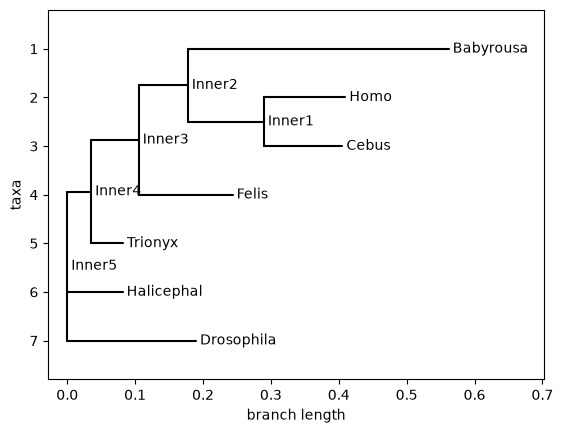

In [18]:
calculator = DistanceCalculator("identity")
constructor = DistanceTreeConstructor(calculator)
tree = constructor.build_tree(alignment)  # по умолчанию использует метод UPGMA (можно передать calculator)

Phylo.draw_ascii(tree)
Phylo.draw(tree)